In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [43]:
# Check our Python environment
print("Python is ready for EDA!")


Python is ready for EDA!


In [44]:
import urllib.request
import zipfile
import os

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

zip_file = "online_retail.zip"

print("Downloading dataset...")

urllib.request.urlretrieve(url, zip_file)

print("Download completed!")

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(".")

print("Dataset extracted!")
print(os.listdir("."))

Download completed!
Dataset extracted!
['.config', 'online_retail.zip', 'Online Retail.xlsx', 'sample_data']


In [45]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [46]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [47]:
df.shape

(541909, 8)

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [49]:
df.describe()


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [50]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [51]:
(df["Quantity"] < 0).sum()

np.int64(10624)

In [52]:
(df["Quantity"] == 0).sum()

np.int64(0)

In [53]:
(df["UnitPrice"] < 0).sum()

np.int64(2)

In [54]:
(df["UnitPrice"] == 0).sum()

np.int64(2515)

In [55]:
df.duplicated().sum()

np.int64(5268)

In [56]:
df["InvoiceNo"].astype(str).str.startswith("C").sum()

np.int64(9288)

In [57]:
df.duplicated().sum()


np.int64(5268)

In [58]:
(df["Quantity"] < 0).sum()

np.int64(10624)

In [59]:
(df["UnitPrice"] < 0).sum()

np.int64(2)

In [60]:
df[df["Quantity"] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [61]:
df[df["Quantity"] < 0]["InvoiceNo"].astype(str).str.startswith("C").value_counts()

,count
InvoiceNo,
True,9288
False,1336


In [62]:
df[df["UnitPrice"] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [63]:
df_clean = df.copy()

In [64]:
df_clean = df_clean.drop_duplicates()

In [65]:
df_clean = df_clean[~df_clean["InvoiceNo"].astype(str).str.startswith("C")]

In [66]:
df_clean = df_clean[df_clean["Quantity"] > 0]

In [67]:
df_clean = df_clean[df_clean["UnitPrice"] >= 0]

In [68]:
df_clean.shape

(526052, 8)

In [69]:
df_clean.duplicated().sum()

np.int64(0)

In [70]:
(df_clean["Quantity"] < 0).sum()

np.int64(0)

In [71]:
(df_clean["UnitPrice"] < 0).sum()

np.int64(0)

In [72]:
# ==========================================
# ONLINE RETAIL DATA - DATA CLEANING
# ==========================================

# 1. Create a copy of the original dataset
df_clean = df.copy()

# 2. Check original shape
print("Original dataset shape:", df_clean.shape)

# 3. Remove exact duplicate rows
duplicates = df_clean.duplicated().sum()
print("Duplicate rows found:", duplicates)

df_clean = df_clean.drop_duplicates()

# 4. Remove cancelled invoices
cancelled = df_clean["InvoiceNo"].astype(str).str.startswith("C").sum()
print("Cancelled invoices found:", cancelled)

df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# 5. Remove negative quantities
negative_quantity = (df_clean["Quantity"] < 0).sum()
print("Negative quantity records found:", negative_quantity)

df_clean = df_clean[df_clean["Quantity"] > 0]

# 6. Remove negative prices
negative_price = (df_clean["UnitPrice"] < 0).sum()
print("Negative price records found:", negative_price)

df_clean = df_clean[df_clean["UnitPrice"] >= 0]

# 7. Create TotalSales column
df_clean["TotalSales"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# 8. Final dataset shape
print("\nFinal dataset shape:", df_clean.shape)

# 9. Verify duplicates
print("Remaining duplicates:", df_clean.duplicated().sum())

# 10. Verify negative quantities
print(
    "Remaining negative quantities:",
    (df_clean["Quantity"] < 0).sum()
)

# 11. Verify negative prices
print(
    "Remaining negative prices:",
    (df_clean["UnitPrice"] < 0).sum()
)

# 12. Check missing values
print("\nMissing values:")
print(df_clean.isnull().sum())

# 13. Display first 5 rows
print("\nFirst 5 rows:")
display(df_clean.head())

Original dataset shape: (541909, 8)
Duplicate rows found: 5268
Cancelled invoices found: 9251
Negative quantity records found: 1336
Negative price records found: 2

Final dataset shape: (526052, 9)
Remaining duplicates: 0
Remaining negative quantities: 0
Remaining negative prices: 0

Missing values:
InvoiceNo           0
StockCode           0
Description       592
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     133320
Country             0
TotalSales          0
dtype: int64

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [73]:
# ==========================================
# STEP 5 — SALES ANALYSIS
# ==========================================

# 1. Total Revenue
total_revenue = df_clean["TotalSales"].sum()

print("Total Revenue: £", round(total_revenue, 2))


# 2. Total Units Sold
total_units = df_clean["Quantity"].sum()

print("Total Units Sold:", total_units)


# 3. Number of Transactions
total_transactions = df_clean["InvoiceNo"].nunique()

print("Total Transactions:", total_transactions)


# 4. Number of Products
total_products = df_clean["StockCode"].nunique()

print("Total Unique Products:", total_products)


# 5. Number of Customers
total_customers = df_clean["CustomerID"].nunique()

print("Total Unique Customers:", total_customers)


# 6. Average Order Value
average_order_value = (
    df_clean.groupby("InvoiceNo")["TotalSales"].sum().mean()
)

print("Average Order Value: £", round(average_order_value, 2))


# 7. Average Quantity per Transaction
average_quantity = (
    df_clean.groupby("InvoiceNo")["Quantity"].sum().mean()
)

print("Average Quantity per Transaction:", round(average_quantity, 2))

Total Revenue: £ 10642110.8
Total Units Sold: 5645017
Total Transactions: 20726
Total Unique Products: 3941
Total Unique Customers: 4339
Average Order Value: £ 513.47
Average Quantity per Transaction: 272.36


In [74]:
# ==========================================
# STEP 5.1 — TOP 10 PRODUCTS BY REVENUE
# ==========================================

top_products_revenue = (
    df_clean
    .groupby("Description")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Revenue:")
display(top_products_revenue)


Top 10 Products by Revenue:


,TotalSales
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82


In [75]:
top_products_quantity = (
    df_clean
    .groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Quantity Sold:")
display(top_products_quantity)

Top 10 Products by Quantity Sold:


,Quantity
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
JUMBO BAG RED RETROSPOT,48375
WHITE HANGING HEART T-LIGHT HOLDER,37876
POPCORN HOLDER,36749
PACK OF 72 RETROSPOT CAKE CASES,36396
ASSORTED COLOUR BIRD ORNAMENT,36362
RABBIT NIGHT LIGHT,30739


In [76]:
# ==========================================
# STEP 5.2 — COUNTRY-WISE SALES ANALYSIS
# ==========================================

country_sales = (
    df_clean
    .groupby("Country")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Countries by Revenue:")
display(country_sales.head(10))

Top 10 Countries by Revenue:


,TotalSales
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


In [77]:
country_orders = (
    df_clean
    .groupby("Country")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Countries by Number of Orders:")
display(country_orders.head(10))

Top 10 Countries by Number of Orders:


,InvoiceNo
Country,
United Kingdom,18784
Germany,457
France,392
EIRE,288
Belgium,98
Netherlands,95
Spain,90
Portugal,58
Australia,57


In [78]:
country_customers = (
    df_clean
    .groupby("Country")["CustomerID"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Countries by Customers:")
display(country_customers.head(10))

Top 10 Countries by Customers:


,CustomerID
Country,
United Kingdom,3921
Germany,94
France,87
Spain,30
Belgium,25
Switzerland,21
Portugal,19
Italy,14
Finland,12


## 6. Monthly Sales Trend Analysis

This analysis examines monthly revenue patterns to identify peak sales periods, seasonal trends, and changes in business performance over time.

In [79]:
# Monthly Sales Trend Analysis

# Check required columns
print(df_clean.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalSales']


Monthly Revenue:


,TotalSales
InvoiceDate,
2010-12-01,821452.730
2011-01-01,689811.610
2011-02-01,522545.560
2011-03-01,716215.260
2011-04-01,536968.491
2011-05-01,769296.610
2011-06-01,760547.010
2011-07-01,718076.121
2011-08-01,757841.380


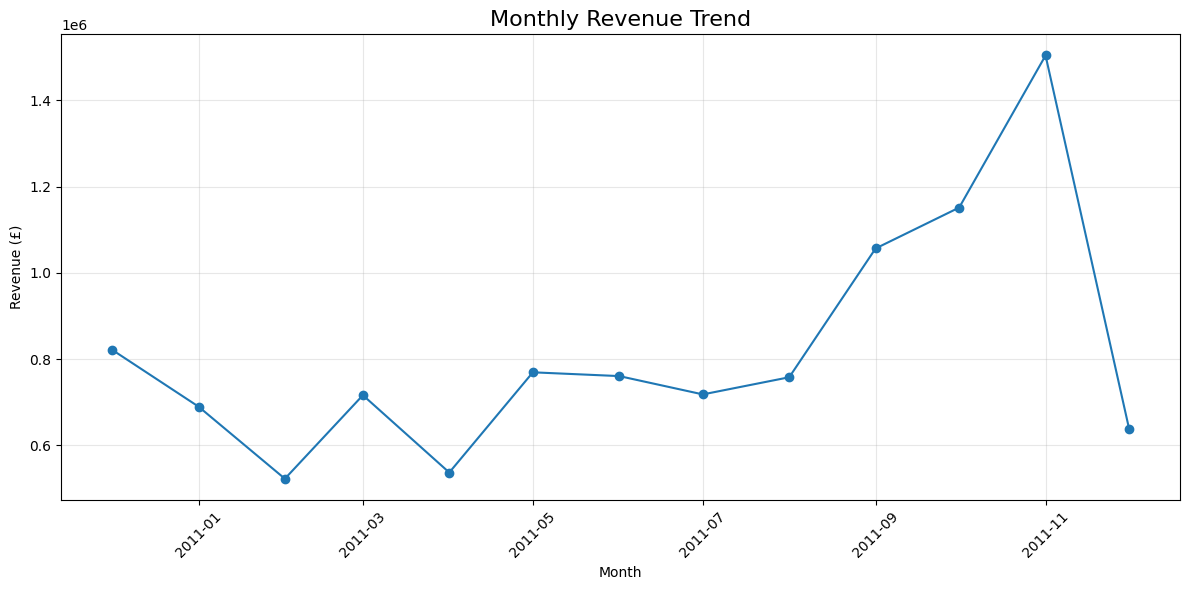

In [80]:

# STEP 6: MONTHLY SALES TREND ANALYSIS

import matplotlib.pyplot as plt
import pandas as pd

# Ensure InvoiceDate is in datetime format
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

# Calculate monthly revenue
monthly_sales = (
    df_clean
    .set_index("InvoiceDate")["TotalSales"]
    .resample("MS")
    .sum()
)

# Display monthly revenue
print("Monthly Revenue:")
display(monthly_sales)

# Plot monthly sales trend
plt.figure(figsize=(12, 6))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Key Insights — Monthly Sales Trend

- November 2011 recorded the highest monthly revenue at £1.50 million.
- February 2011 recorded the lowest monthly revenue at approximately £522,546.
- Revenue increased substantially between August and November 2011, suggesting a strong end-of-year sales period.
- Revenue declined in December 2011 to approximately £637,790.

### Business Recommendation

The business should investigate the factors driving the strong sales performance in September–November, such as seasonal demand, promotions, and product availability. These findings can help improve inventory planning and marketing strategies for future peak sales periods.

*Note: Revenue trends alone do not establish the cause of sales changes. Further analysis is needed to confirm the underlying factors.*

## 7. Customer Purchase Analysis

This analysis identifies the highest-value customers based on total revenue and examines customer purchasing patterns to understand their contribution to business performance.


Top 10 Customers by Revenue:


,TotalSales
CustomerID,
14646.0,280206.02
18102.0,259657.30
17450.0,194390.79
16446.0,168472.50
14911.0,143711.17
12415.0,124914.53
14156.0,117210.08
17511.0,91062.38
16029.0,80850.84


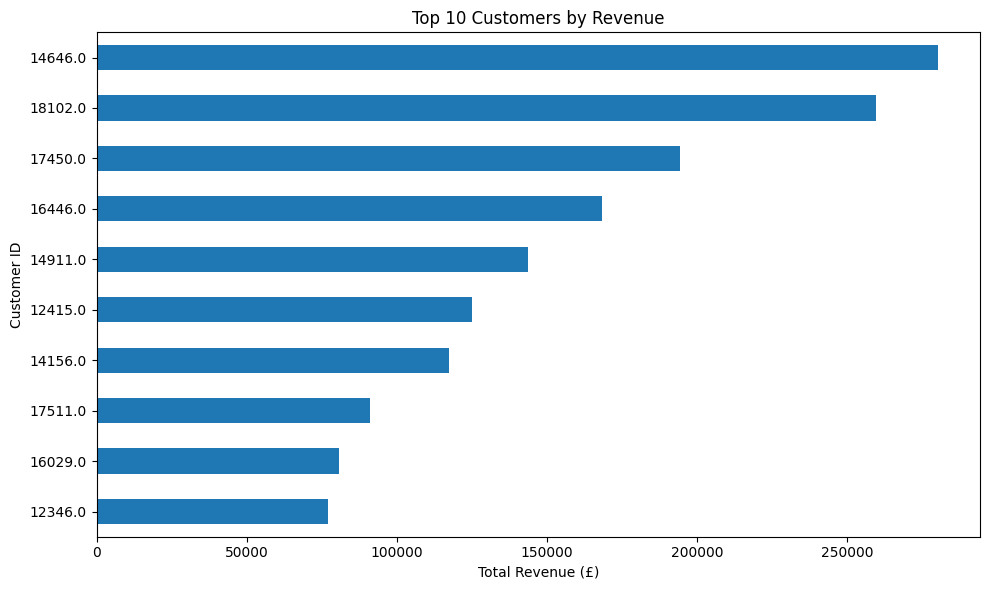

In [81]:

# STEP 7: CUSTOMER PURCHASE ANALYSIS

# Calculate revenue generated by each customer
customer_sales = (
    df_clean.groupby("CustomerID")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 customers
top_10_customers = customer_sales.head(10)

print("Top 10 Customers by Revenue:")
display(top_10_customers)

# Visualize the top 10 customers
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
top_10_customers.sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()


### Key Insights — Customer Purchase Analysis

- Customer ID 14646 generated the highest revenue of £280,206.02.
- Customer ID 18102 ranked second, contributing £259,657.30.
- The top 10 customers generated approximately £1.54 million in combined revenue.
- The results indicate that certain customers account for substantial transaction revenue.

### Business Recommendations

- Maintain strong relationships with high-value customers through personalized offers and loyalty programs.
- Analyze purchase frequency and order patterns to understand customer retention.
- Identify opportunities to encourage repeat purchases among customers with lower spending.

*Note: Revenue contribution alone does not establish customer profitability or loyalty. Purchase frequency and profit analysis are needed for those conclusions.*

In [82]:

# STEP 8: REPEAT CUSTOMER ANALYSIS

# Count unique invoices for each customer
customer_orders = (
    df_clean.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

# Identify repeat customers
repeat_customers = customer_orders[customer_orders > 1]

total_customers = customer_orders.nunique()
repeat_count = len(repeat_customers)
one_time_count = len(customer_orders[customer_orders == 1])

repeat_percentage = (repeat_count / len(customer_orders)) * 100

print("Total customers:", len(customer_orders))
print("Repeat customers:", repeat_count)
print("Customers with one invoice:", one_time_count)
print(f"Repeat customer percentage: {repeat_percentage:.2f}%")


Total customers: 4339
Repeat customers: 2845
Customers with one invoice: 1494
Repeat customer percentage: 65.57%


### Key Insights — Repeat Customer Analysis

- The dataset contains 4,339 identifiable customers.
- A total of 2,845 customers had more than one distinct invoice, representing 65.57% of customers.
- The remaining 1,494 customers had only one distinct invoice, representing 34.43%.
- The results show that repeat purchasing is common among customers with identifiable customer IDs.

### Business Recommendations

- Encourage repeat purchases through personalized promotions and loyalty programs.
- Investigate why one-invoice customers did not make additional recorded purchases.
- Monitor repeat-purchase behavior over time to evaluate customer engagement.

*Note: Having multiple invoices in the dataset indicates repeat purchasing, but does not by itself prove long-term customer retention.*

Top 10 Countries by Revenue:


,TotalSales
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


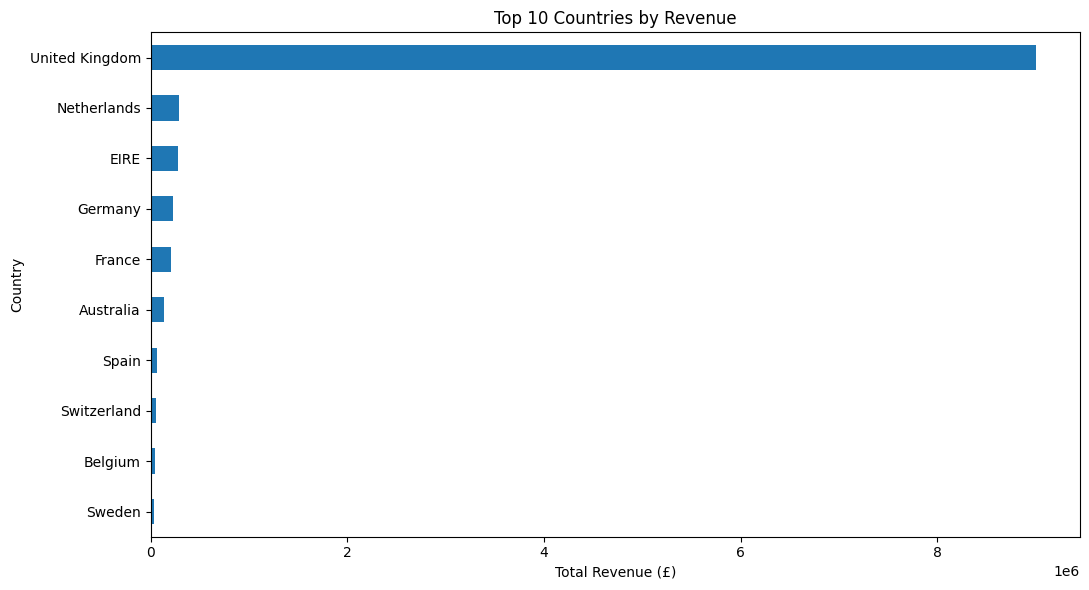

In [83]:

# STEP 9: COUNTRY-WISE REVENUE ANALYSIS

country_sales = (
    df_clean.groupby("Country")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 countries
top_10_countries = country_sales.head(10)

print("Top 10 Countries by Revenue:")
display(top_10_countries)

# Visualize country-wise revenue
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))
top_10_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


### Key Insights — Country-wise Revenue Analysis

- The United Kingdom recorded the highest revenue at approximately £9.00 million.
- The Netherlands ranked second, generating approximately £285,446.
- EIRE ranked third, contributing approximately £283,141.
- Revenue is heavily concentrated in the United Kingdom compared with the other countries in the top 10.

### Business Recommendations

- Maintain inventory availability and customer service quality in the UK, the primary revenue market.
- Explore opportunities to expand sales in other countries, particularly the Netherlands, EIRE, Germany, and France.
- Analyze country-wise order volume and average order value to better understand the differences in revenue.

*Note: Revenue concentration does not necessarily indicate profit concentration. Country-wise profitability and order volume should be investigated separately.*

Top 10 Products by Quantity Sold:


,Total_Quantity,Total_Revenue
Description,,
"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01
JUMBO BAG RED RETROSPOT,48375,94159.81
WHITE HANGING HEART T-LIGHT HOLDER,37876,106236.72
POPCORN HOLDER,36749,34288.67
PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45
ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62
RABBIT NIGHT LIGHT,30739,66870.03


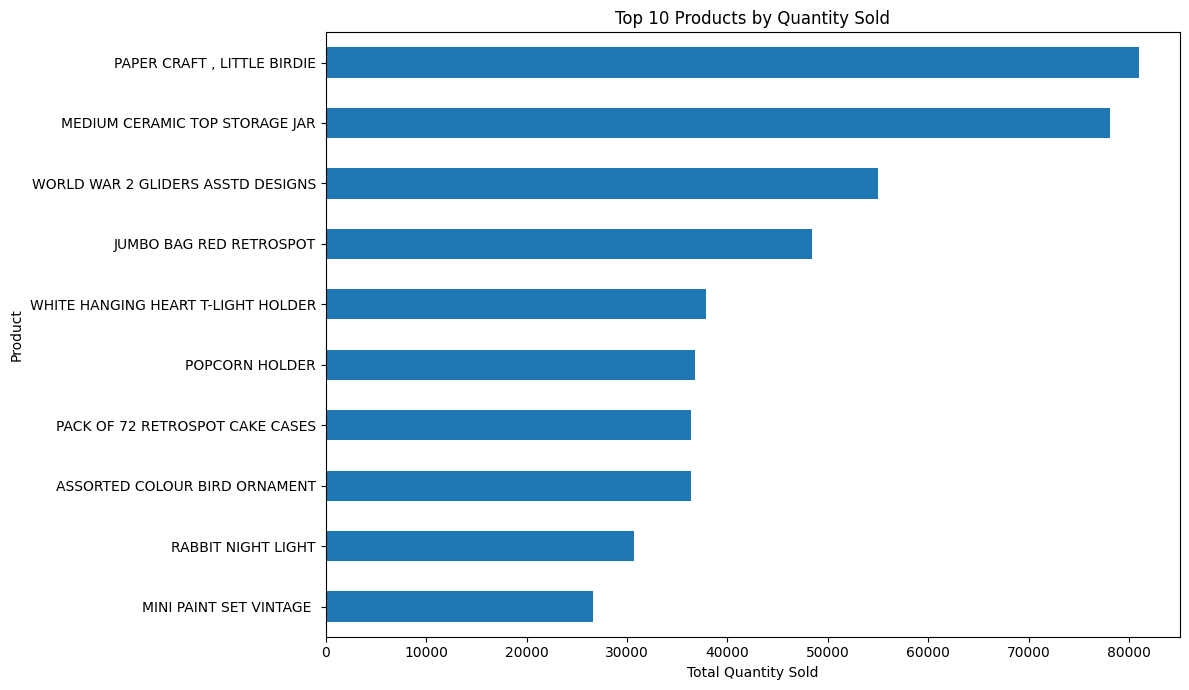

In [84]:

# STEP 10: PRODUCT PERFORMANCE ANALYSIS

product_sales = (
    df_clean.groupby("Description")
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("TotalSales", "sum")
    )
    .sort_values("Total_Quantity", ascending=False)
)

# Display the top 10 products by quantity
top_10_products = product_sales.head(10)

print("Top 10 Products by Quantity Sold:")
display(top_10_products)

# Visualize quantity sold
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))
top_10_products["Total_Quantity"].sort_values().plot(kind="barh")

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


### Key Insights — Product Performance Analysis

- PAPER CRAFT, LITTLE BIRDIE recorded the highest total quantity sold, at 80,995 units.
- MEDIUM CERAMIC TOP STORAGE JAR ranked second, with 78,033 units sold.
- JUMBO BAG RED RETROSPOT generated £94,159.81 in revenue from 48,375 units.
- Product rankings differ depending on whether performance is measured by quantity sold or revenue.

### Business Recommendations

- Maintain appropriate inventory levels for products with consistently high demand.
- Analyze both quantity sold and revenue when deciding which products to prioritize.
- Investigate product-level profitability, returns, and sales trends before making inventory or pricing decisions.

*Note: Quantity sold alone does not establish profitability. Returns and cancelled transactions should be handled consistently when interpreting product performance.*


Top 10 Products by Revenue:


,TotalSales
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82


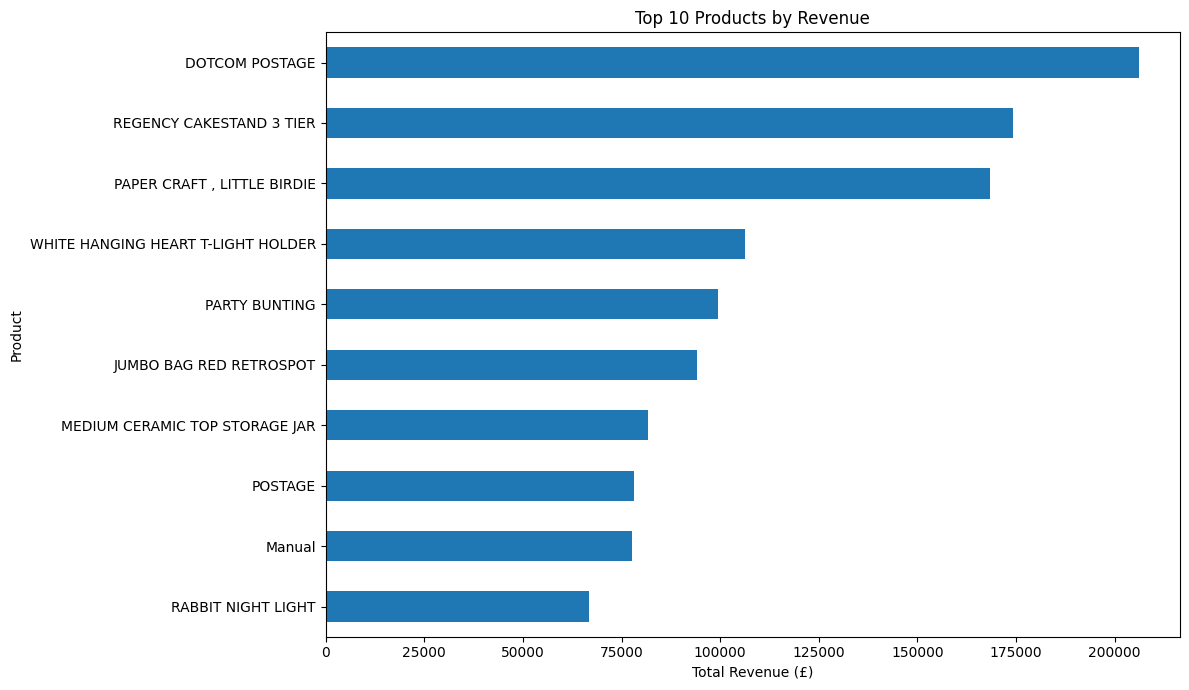

In [85]:

# STEP 11: TOP PRODUCTS BY REVENUE

top_products_revenue = (
    df_clean.groupby("Description")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Revenue:")
display(top_products_revenue)

# Visualize top products by revenue
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))
top_products_revenue.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


### Key Insights — Top Products by Revenue

- DOTCOM POSTAGE recorded the highest revenue at £206,248.77.
- REGENCY CAKESTAND 3 TIER ranked second, generating £174,156.54.
- PAPER CRAFT, LITTLE BIRDIE generated £168,469.60 and was also the highest-ranked product by quantity sold.
- The products with the highest revenue are not necessarily those with the highest sales quantities.
- Postage and manual entries appear among the top revenue categories and should be separated from physical merchandise when interpreting product performance.

### Business Recommendations

- Evaluate merchandise performance separately from postage and manual entries.
- Use both revenue and quantity sold to inform inventory decisions.
- Analyze product-level profit margins and return rates before deciding which items are most valuable to the business.

In [86]:
# Final data-quality check
print("Missing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

print("\nDate range:")
print(df_clean["InvoiceDate"].min())
print(df_clean["InvoiceDate"].max())

print("\nNegative quantities:", (df_clean["Quantity"] < 0).sum())
print("Negative unit prices:", (df_clean["UnitPrice"] < 0).sum())

Missing values:
InvoiceNo           0
StockCode           0
Description       592
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     133320
Country             0
TotalSales          0
dtype: int64

Duplicate rows: 0

Date range:
2010-12-01 08:26:00
2011-12-09 12:50:00

Negative quantities: 0
Negative unit prices: 0


In [87]:

# Verify sales calculations and cancellation invoices

cancellations = df_clean["InvoiceNo"].astype(str).str.startswith("C").sum()

sales_mismatch = (
    (df_clean["Quantity"] * df_clean["UnitPrice"] - df_clean["TotalSales"])
    .abs()
    .gt(0.01)
    .sum()
)

print("Cancellation invoice rows:", cancellations)
print("Rows with inconsistent TotalSales:", sales_mismatch)
print("Total calculated sales: £{:,.2f}".format(df_clean["TotalSales"].sum()))


Cancellation invoice rows: 0
Rows with inconsistent TotalSales: 0
Total calculated sales: £10,642,110.80


# Final Conclusion

This exploratory data analysis (EDA) project examined an Online Retail dataset to identify sales trends, customer purchasing patterns, country-wise performance, and top-performing products.

## Key Findings

- **Sales trends:** Monthly sales varied throughout the observation period, with November 2011 recording the highest monthly sales value.
- **Customer analysis:** The dataset contained 4,339 identifiable customers, of whom 2,845 had placed more than one distinct invoice.
- **Geographical performance:** The United Kingdom contributed the largest share of sales value among the countries analysed.
- **Product performance:** Product rankings differed depending on whether performance was measured by quantity sold or sales value.
- **Data quality:** The cleaned dataset contained 526,052 rows, no exact duplicate rows, and no negative quantities or negative unit prices.
- **Sales validation:** The `TotalSales` calculations were consistent with quantity multiplied by unit price. The total sales value in the cleaned dataset was £10,642,110.80.

## Recommendations

1. Investigate monthly sales patterns to identify periods of higher and lower demand.
2. Develop customer retention strategies for customers who have made only one purchase.
3. Examine international markets to identify opportunities for expansion.
4. Evaluate products using both quantity sold and sales value instead of relying on a single metric.
5. Improve customer identification and investigate missing product descriptions to support more reliable analysis.

## Limitations

Approximately 25.3% of the cleaned rows have missing customer IDs, which limits customer-level analysis. Since cancellation and negative-quantity records are absent from the cleaned dataset, the reported total should not be interpreted as verified net revenue after returns. Further analysis of the original data would be required to quantify cancellations and returns accurately.

## Conclusion

This project demonstrates how Python, Pandas, Matplotlib, and Seaborn can be used to clean retail data, validate calculations, visualize trends, and extract actionable business insights. The findings can help support data-driven decisions in sales planning, customer retention, and product management.